# Phase 5 — Data Science and Predictive Intelligence

## Objective
Predict simulated trade reporting rejection risk using information
available before submission.

## Step 5.1 — Synthetic Modelling History
Generate approximately 2,000 reproducible synthetic trades.

Requirements:
- Keep modelling data separate from the 50 UAT trades.
- Preserve trade IDs, versions and timestamps.
- Generate simulated reporting outcomes.
- Record the random seed.
- Prevent future information from entering prediction features.

In [1]:
import numpy as np
import pandas as pd

SEED = 42
rng = np.random.default_rng(SEED)

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Random seed:", SEED)

Pandas: 3.0.6
NumPy: 2.5.3
Random seed: 42


In [2]:
## Generate 2,000 synthetic trades
n = 2000

trade_dates = (
    pd.Timestamp("2024-01-01")
    + pd.to_timedelta(
        np.sort(rng.integers(0, 730, size=n)),
        unit="D"
    )
)

df = pd.DataFrame({
    "trade_id": [f"H-{i:05d}" for i in range(1, n + 1)],
    "trade_version": 1,
    "trade_timestamp": trade_dates,
    "product_type": "GBP_IRS",
    "currency": "GBP",
    "notional_amount": rng.choice(
        [1_000_000, 5_000_000, 10_000_000,
         25_000_000, 50_000_000, 100_000_000],
        size=n
    ),
    "tenor_years": rng.choice(
        [1, 2, 5, 7, 10, 15, 20],
        size=n
    ),
    "counterparty_id": rng.choice(
        ["CP-001", "CP-002", "CP-003", "CP-004", "CP-005"],
        size=n
    )
})

# Synthetic reporting-risk mechanism
risk = (
    0.04
    + 0.08 * (df["notional_amount"] >= 50_000_000)
    + 0.07 * (df["tenor_years"] >= 15)
    + 0.06 * (df["counterparty_id"] == "CP-004")
)

df["simulated_rejected"] = (
    rng.random(n) < risk
).astype(int)

# Outcome occurs after the prediction point
df["report_outcome_timestamp"] = (
    df["trade_timestamp"]
    + pd.Timedelta(hours=2)
)

df.head()

,trade_id,trade_version,trade_timestamp,product_type,currency,notional_amount,tenor_years,counterparty_id,simulated_rejected,report_outcome_timestamp
0,H-00001,1,2024-01-01,GBP_IRS,GBP,100000000,5,CP-004,0,2024-01-01 02:00:00
1,H-00002,1,2024-01-02,GBP_IRS,GBP,1000000,15,CP-005,0,2024-01-02 02:00:00
2,H-00003,1,2024-01-02,GBP_IRS,GBP,10000000,1,CP-004,0,2024-01-02 02:00:00
3,H-00004,1,2024-01-02,GBP_IRS,GBP,10000000,7,CP-003,0,2024-01-02 02:00:00
4,H-00005,1,2024-01-02,GBP_IRS,GBP,50000000,15,CP-003,0,2024-01-02 02:00:00


In [3]:
## Save and verify
from pathlib import Path
'''
output_dir = Path("data\Synthetic_data")
output_dir.mkdir(parents=True, exist_ok=True)

df.to_csv(
    output_dir / "synthetic_trade_history.csv",
    index=False
)

print("Total records:", len(df))
print("Unique trades:", df["trade_id"].nunique())
print("Missing values:", df.isna().sum().sum())
print("Duplicate trade versions:",
      df.duplicated(["trade_id", "trade_version"]).sum())

print("\nSimulated outcomes:")
print(df["simulated_rejected"].value_counts())

print("\nRejection prevalence:")
print(df["simulated_rejected"].mean().round(4))

'''

<>:4: SyntaxWarning: invalid escape sequence '\S'
<>:4: SyntaxWarning: invalid escape sequence '\S'
C:\Users\singh\AppData\Local\Temp\ipykernel_68072\605500301.py:4: SyntaxWarning: invalid escape sequence '\S'
  output_dir = Path("data\Synthetic_data")


'\noutput_dir = Path("data\\Synthetic_data")\noutput_dir.mkdir(parents=True, exist_ok=True)\n\ndf.to_csv(\n    output_dir / "synthetic_trade_history.csv",\n    index=False\n)\n\nprint("Total records:", len(df))\nprint("Unique trades:", df["trade_id"].nunique())\nprint("Missing values:", df.isna().sum().sum())\nprint("Duplicate trade versions:",\n      df.duplicated(["trade_id", "trade_version"]).sum())\n\nprint("\nSimulated outcomes:")\nprint(df["simulated_rejected"].value_counts())\n\nprint("\nRejection prevalence:")\nprint(df["simulated_rejected"].mean().round(4))\n\n'

## 5.2 — Target Definition and Feature Specification

### Prediction Target
Predict whether an OTC trade will receive a simulated reporting rejection.

- Target: simulated_rejected
- 0 = Accepted
- 1 = Rejected

### Prediction Timestamp
The trade execution timestamp is used as the scoring point
for this initial demonstration.

Only information available at or before this timestamp
can be used as model input.

### Data Sources
- Synthetic history: Model training, validation and testing
- CME real GBP OIS data: Input compatibility testing only

Actual reporting outcomes are not available in the CME dataset.

In [4]:
synthetic_df = pd.read_csv(
    "data/Synthetic_data/synthetic_trade_history.csv"
)

synthetic_df["trade_timestamp"] = pd.to_datetime(
    synthetic_df["trade_timestamp"],
    format="%d/%m/%Y"
)

synthetic_df["report_outcome_timestamp"] = pd.to_datetime(
    synthetic_df["report_outcome_timestamp"],
    format="%d/%m/%Y %H:%M"
)

print(synthetic_df.dtypes)
synthetic_df.head()

trade_id                               str
trade_version                        int64
trade_timestamp             datetime64[us]
product_type                           str
currency                               str
notional_amount                      int64
tenor_years                          int64
counterparty_id                        str
simulated_rejected                   int64
report_outcome_timestamp    datetime64[us]
dtype: object


,trade_id,trade_version,trade_timestamp,product_type,currency,notional_amount,tenor_years,counterparty_id,simulated_rejected,report_outcome_timestamp
0,H-00001,1,2024-01-01,GBP_IRS,GBP,100000000,5,CP-004,0,2024-01-01 02:00:00
1,H-00002,1,2024-01-02,GBP_IRS,GBP,1000000,15,CP-005,0,2024-01-02 02:00:00
2,H-00003,1,2024-01-02,GBP_IRS,GBP,10000000,1,CP-004,0,2024-01-02 02:00:00
3,H-00004,1,2024-01-02,GBP_IRS,GBP,10000000,7,CP-003,0,2024-01-02 02:00:00
4,H-00005,1,2024-01-02,GBP_IRS,GBP,50000000,15,CP-003,0,2024-01-02 02:00:00


In [5]:
TARGET = "simulated_rejected"

FEATURES = [
    "notional_amount",
    "tenor_years",
    "currency",
    "product_type",
    "counterparty_id"
]

X = synthetic_df[FEATURES].copy()
y = synthetic_df[TARGET].copy()

print("Features:", X.columns.tolist())
print("Target:", TARGET)

print("\nClass distribution:")
print(y.value_counts())

print("\nClass prevalence:")
print(y.value_counts(normalize=True).round(4))

Features: ['notional_amount', 'tenor_years', 'currency', 'product_type', 'counterparty_id']
Target: simulated_rejected

Class distribution:
simulated_rejected
0    1811
1     189
Name: count, dtype: int64

Class prevalence:
simulated_rejected
0    0.9055
1    0.0945
Name: proportion, dtype: float64


In [6]:
## Check for data leakage
# Confirm reporting outcomes occur after scoring
invalid_timestamps = (
    synthetic_df["report_outcome_timestamp"]
    <= synthetic_df["trade_timestamp"]
).sum()

# Ensure prohibited fields are excluded
LEAKAGE_COLUMNS = [
    "simulated_rejected",
    "report_outcome_timestamp",
    "reject_code",
    "correction_outcome"
]

leakage_features = set(FEATURES).intersection(LEAKAGE_COLUMNS)

print("Invalid outcome timestamps:", invalid_timestamps)
print("Leaking features:", leakage_features)

assert invalid_timestamps == 0
assert not leakage_features

Invalid outcome timestamps: 0
Leaking features: set()


### Feature Specification

| Field | Role | Description |
|---|---|---|
| notional_amount | Numerical feature | GBP trade notional |
| tenor_years | Numerical feature | Swap maturity in years |
| currency | Categorical feature | Trade currency |
| product_type | Categorical feature | Interest rate swap classification |
| counterparty_id | Categorical feature | Synthetic counterparty identifier |
| simulated_rejected | Target | Later simulated reporting outcome |
| trade_timestamp | Split/scoring timestamp | Time of trade execution |
| report_outcome_timestamp | Audit only | Later reporting outcome timestamp |

### Leakage Controls
- Exclude target and future reporting outcomes from model inputs.
- Fit preprocessing only on training data.
- Keep all versions of each trade in the same dataset split.
- Preserve the held-out test set for final evaluation.

## 5.3 — Time-Based Train, Validation & Test Split

In [7]:
# Sort by trade timestamp
df_sorted = synthetic_df.sort_values(
    ["trade_timestamp", "trade_id", "trade_version"]
).reset_index(drop=True)

print("Total records:", len(df_sorted))
print("Date range:",
      df_sorted["trade_timestamp"].min(),
      "to",
      df_sorted["trade_timestamp"].max())

Total records: 2000
Date range: 2024-01-01 00:00:00 to 2025-12-30 00:00:00


In [8]:
## Create time-based splits

# Use each trade's earliest timestamp for grouping
trade_order = (
    df_sorted.groupby("trade_id")["trade_timestamp"]
    .min()
    .sort_values()
)

n_trades = len(trade_order)

train_end = int(n_trades * 0.70)
val_end = int(n_trades * 0.85)

train_ids = set(trade_order.index[:train_end])
val_ids = set(trade_order.index[train_end:val_end])
test_ids = set(trade_order.index[val_end:])

train_df = df_sorted[df_sorted["trade_id"].isin(train_ids)].copy()
val_df = df_sorted[df_sorted["trade_id"].isin(val_ids)].copy()
test_df = df_sorted[df_sorted["trade_id"].isin(test_ids)].copy()

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Training: (1400, 10)
Validation: (300, 10)
Test: (300, 10)


In [9]:
for data in [train_df, val_df, test_df]:
    data["trade_timestamp"] = pd.to_datetime(
        data["trade_timestamp"],
        format="%d/%m/%Y"
    )

In [10]:
## Define X and y for each dataset

X_train = train_df[FEATURES]
y_train = train_df[TARGET]

X_val = val_df[FEATURES]
y_val = val_df[TARGET]

X_test = test_df[FEATURES]
y_test = test_df[TARGET]

print("Training rejection rate:", round(y_train.mean() * 100, 2), "%")
print("Validation rejection rate:", round(y_val.mean() * 100, 2), "%")
print("Test rejection rate:", round(y_test.mean() * 100, 2), "%")

Training rejection rate: 9.0 %
Validation rejection rate: 11.33 %
Test rejection rate: 9.67 %


In [11]:
## Verify chronological order
for name, data in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(
        name,
        "| Start:", data["trade_timestamp"].min(),
        "| End:", data["trade_timestamp"].max()
    )

print(
    "\nChronological order:",
    train_df["trade_timestamp"].max()
    <= val_df["trade_timestamp"].min()
    <= test_df["trade_timestamp"].min()
)

Train | Start: 2024-01-01 00:00:00 | End: 2025-05-29 00:00:00
Validation | Start: 2025-05-30 00:00:00 | End: 2025-09-12 00:00:00
Test | Start: 2025-09-12 00:00:00 | End: 2025-12-30 00:00:00

Chronological order: True


## 5.4 — Baseline Model Training

In [12]:
import numpy as np

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    confusion_matrix
)

In [13]:
numeric_features = [
    "notional_amount",
    "tenor_years"
]

categorical_features = [
    "currency",
    "product_type",
    "counterparty_id"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

In [14]:
dummy_model = DummyClassifier(
    strategy="prior"
)

dummy_model.fit(X_train, y_train)

dummy_probs = dummy_model.predict_proba(X_val)[:, 1]

dummy_predictions = dummy_model.predict(X_val)

In [15]:
## Train Logistic Regression Original
lr_model_org = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

lr_model_org.fit(X_train, y_train)

lr_probs_org = lr_model_org.predict_proba(X_val)[:, 1]

lr_predictions_org = lr_model_org.predict(X_val)

In [16]:
## Train Logistic Regression (balanced class)
lr_model_bal= Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

lr_model_bal.fit(X_train, y_train)

lr_probs_bal = lr_model_bal.predict_proba(X_val)[:, 1]

lr_predictions_bal = lr_model_bal.predict(X_val)

In [17]:
## Compare validation metrics (Dummy vs Logistic original)
def evaluate_model(name, y_true, y_pred, y_prob):
    return {
        "Model": name,
        "PR-AUC": average_precision_score(y_true, y_prob),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        )
    }

results = pd.DataFrame([
    evaluate_model(
        "Dummy Classifier",
        y_val,
        dummy_predictions,
        dummy_probs
    ),
    evaluate_model(
        "Logistic Regression Original",
        y_val,
        lr_predictions_org,
        lr_probs_org
    )
])

display(results.round(4))

,Model,PR-AUC,Precision,Recall
0,Dummy Classifier,0.1133,0.0,0.0
1,Logistic Regression Original,0.2328,0.0,0.0


In [18]:
## Compare validation metrics (Dummy vs Logistic original)
def evaluate_model(name, y_true, y_pred, y_prob):
    return {
        "Model": name,
        "PR-AUC": average_precision_score(y_true, y_prob),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        )
    }

results2 = pd.DataFrame([
    evaluate_model(
        "Dummy Classifier",
        y_val,
        dummy_predictions,
        dummy_probs
    ),
    evaluate_model(
        "Logistic Regression Balanced",
        y_val,
        lr_predictions_bal,
        lr_probs_bal
    )
])

display(results2.round(4))

,Model,PR-AUC,Precision,Recall
0,Dummy Classifier,0.1133,0.0000,0.0000
1,Logistic Regression Balanced,0.2339,0.2037,0.6471


In [19]:
## Confusion matrices (Dummy vs Logistics Original)
print("Dummy Classifier:")
print(confusion_matrix(y_val, dummy_predictions))

print("\nLogistic Regression Original:")
print(confusion_matrix(y_val, lr_predictions_org))

Dummy Classifier:
[[266   0]
 [ 34   0]]

Logistic Regression Original:
[[266   0]
 [ 34   0]]


In [20]:
## Confusion matrices (Dummy vs Logistics balanced)
print("Dummy Classifier:")
print(confusion_matrix(y_val, dummy_predictions))

print("\nLogistic Regression Original:")
print(confusion_matrix(y_val, lr_predictions_bal))

Dummy Classifier:
[[266   0]
 [ 34   0]]

Logistic Regression Original:
[[180  86]
 [ 12  22]]


In [21]:
## Validation Threshold(0.05, 0.51, 0.05) Selection for Logistics(Original)

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

thresholds = np.arange(0.05, 0.51, 0.05)

threshold_results = []

for threshold in thresholds:
    predictions = (lr_probs_org >= threshold).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(3))

,Threshold,Precision,Recall,F1
0,0.05,0.120,0.912,0.212
1,0.10,0.221,0.559,0.317
2,0.15,0.258,0.235,0.246
3,0.20,0.143,0.029,0.049
4,0.25,0.000,0.000,0.000
5,0.30,0.000,0.000,0.000
6,0.35,0.000,0.000,0.000
7,0.40,0.000,0.000,0.000
8,0.45,0.000,0.000,0.000
9,0.50,0.000,0.000,0.000


In [25]:
 ### Different threshold(0.01, 1.01, 0.01) selection for Logistics(Original)
threshold_results2 = []

for i in np.arange(0.01, 1.01, 0.01):
    predictions = (lr_probs_org >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    threshold_results2.append({
        "Threshold": round(threshold, 2),
        "False_Positive": fp,
        "False_Negative": fn,
        "True_Positive": tp,
        "Precision": tp / (tp + fp) if tp + fp else 0,
        "Recall": tp / (tp + fn) if tp + fn else 0
    })

threshold2_df = pd.DataFrame(threshold_results2)

# Keep false alarms at or below 40
eligible2 = threshold2_df[
    threshold2_df["False_Positive"] <= 40
]

best_operational2 = eligible2.sort_values(
    ["Recall", "False_Positive"],
    ascending=[False, True]
).iloc[0]

display(best_operational2)



Threshold          0.5
False_Positive     0.0
False_Negative    34.0
True_Positive      0.0
Precision          0.0
Recall             0.0
Name: 0, dtype: float64

In [26]:
def evaluate_thresholds(y_true, probabilities, thresholds):
    rows = []

    for threshold in np.round(thresholds, 2):
        predictions = (np.asarray(probabilities) >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true, predictions, labels=[0, 1]
        ).ravel()

        rows.append({
            "Threshold": threshold,
            "Precision": precision_score(
                y_true, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_true, predictions, zero_division=0
            ),
            "F1": f1_score(y_true, predictions, zero_division=0),
            "True_Negative": tn,
            "False_Positive": fp,
            "False_Negative": fn,
            "True_Positive": tp,
        })

    return pd.DataFrame(rows)


def select_operational_threshold(results, max_false_positives=40):
    eligible = results[
        results["False_Positive"] <= max_false_positives
    ]

    if eligible.empty:
        raise ValueError("No threshold meets the false-positive limit.")

    return eligible.sort_values(
        ["Recall", "False_Positive", "Threshold"],
        ascending=[False, True, True]
    ).iloc[0]

In [27]:
## Logistic Original: 0.05–0.50, best F1
threshold_df_org = evaluate_thresholds(
    y_val, lr_probs_org, np.arange(0.05, 0.51, 0.05)
)

best_row_org = threshold_df_org.loc[threshold_df_org["F1"].idxmax()]
best_threshold_org = float(best_row_org["Threshold"])

lr_tuned_predictions_org = (
    lr_probs_org >= best_threshold_org
).astype(int)

display(threshold_df_org.round(4))
print("\nSelected threshold and metrics:")
display(best_row_org.to_frame("Original — best F1"))
print("\nConfusion matrix:")
print(confusion_matrix(y_val, lr_tuned_predictions_org, labels=[0, 1]))

,Threshold,Precision,Recall,F1,True_Negative,False_Positive,False_Negative,True_Positive
0,0.05,0.1202,0.9118,0.2123,39,227,3,31
1,0.10,0.2209,0.5588,0.3167,199,67,15,19
2,0.15,0.2581,0.2353,0.2462,243,23,26,8
3,0.20,0.1429,0.0294,0.0488,260,6,33,1
4,0.25,0.0000,0.0000,0.0000,266,0,34,0
5,0.30,0.0000,0.0000,0.0000,266,0,34,0
6,0.35,0.0000,0.0000,0.0000,266,0,34,0
7,0.40,0.0000,0.0000,0.0000,266,0,34,0
8,0.45,0.0000,0.0000,0.0000,266,0,34,0
9,0.50,0.0000,0.0000,0.0000,266,0,34,0



Selected threshold and metrics:


,Original — best F1
Threshold,0.100000
Precision,0.220930
Recall,0.558824
F1,0.316667
True_Negative,199.000000
False_Positive,67.000000
False_Negative,15.000000
True_Positive,19.000000



Confusion matrix:
[[199  67]
 [ 15  19]]


In [28]:
## Logistic Balanced: 0.05–0.50, best F1
threshold_df_bal = evaluate_thresholds(
    y_val, lr_probs_bal, np.arange(0.05, 0.51, 0.05)
)

best_row_bal = threshold_df_bal.loc[threshold_df_bal["F1"].idxmax()]
best_threshold_bal = float(best_row_bal["Threshold"])

lr_tuned_predictions_bal = (
    lr_probs_bal >= best_threshold_bal
).astype(int)

display(threshold_df_bal.round(4))
print("\nSelected threshold and metrics:")
display(best_row_bal.to_frame("Balanced — best F1"))
print("\nConfusion matrix:")
print(confusion_matrix(y_val, lr_tuned_predictions_bal, labels=[0, 1]))

,Threshold,Precision,Recall,F1,True_Negative,False_Positive,False_Negative,True_Positive
0,0.05,0.1133,1.0000,0.2036,0,266,0,34
1,0.10,0.1133,1.0000,0.2036,0,266,0,34
2,0.15,0.1133,1.0000,0.2036,0,266,0,34
3,0.20,0.1133,1.0000,0.2036,0,266,0,34
4,0.25,0.1149,1.0000,0.2061,4,262,0,34
5,0.30,0.1170,0.9706,0.2089,17,249,1,33
6,0.35,0.1255,0.9118,0.2206,50,216,3,31
7,0.40,0.1458,0.8235,0.2478,102,164,6,28
8,0.45,0.1633,0.7059,0.2652,143,123,10,24
9,0.50,0.2037,0.6471,0.3099,180,86,12,22



Selected threshold and metrics:


,Balanced — best F1
Threshold,0.500000
Precision,0.203704
Recall,0.647059
F1,0.309859
True_Negative,180.000000
False_Positive,86.000000
False_Negative,12.000000
True_Positive,22.000000



Confusion matrix:
[[180  86]
 [ 12  22]]


In [29]:
## Logistic Original: 0.01–1.00, maximum 40 false positives
threshold_df_org_fine = evaluate_thresholds(
    y_val, lr_probs_org, np.arange(0.01, 1.01, 0.01)
)

best_operational_org = select_operational_threshold(
    threshold_df_org_fine, max_false_positives=40
)

operational_threshold_org = float(best_operational_org["Threshold"])

lr_operational_predictions_org = (
    lr_probs_org >= operational_threshold_org
).astype(int)

display(threshold_df_org_fine.round(4))
print("\nSelected threshold and metrics:")
display(best_operational_org.to_frame("Original — operational"))
print("\nConfusion matrix:")
print(confusion_matrix(
    y_val, lr_operational_predictions_org, labels=[0, 1]
))

,Threshold,Precision,Recall,F1,True_Negative,False_Positive,False_Negative,True_Positive
0,0.01,0.1133,1.0000,0.2036,0,266,0,34
1,0.02,0.1133,1.0000,0.2036,0,266,0,34
2,0.03,0.1133,1.0000,0.2036,0,266,0,34
3,0.04,0.1130,0.9706,0.2025,7,259,1,33
4,0.05,0.1202,0.9118,0.2123,39,227,3,31
...,...,...,...,...,...,...,...,...
95,0.96,0.0000,0.0000,0.0000,266,0,34,0
96,0.97,0.0000,0.0000,0.0000,266,0,34,0
97,0.98,0.0000,0.0000,0.0000,266,0,34,0
98,0.99,0.0000,0.0000,0.0000,266,0,34,0



Selected threshold and metrics:


,Original — operational
Threshold,0.130000
Precision,0.276596
Recall,0.382353
F1,0.320988
True_Negative,232.000000
False_Positive,34.000000
False_Negative,21.000000
True_Positive,13.000000



Confusion matrix:
[[232  34]
 [ 21  13]]


In [30]:
## Logistic Balanced: 0.01–1.00, maximum 40 false positives
threshold_df_bal_fine = evaluate_thresholds(
    y_val, lr_probs_bal, np.arange(0.01, 1.01, 0.01)
)

best_operational_bal = select_operational_threshold(
    threshold_df_bal_fine, max_false_positives=40
)

operational_threshold_bal = float(best_operational_bal["Threshold"])

lr_operational_predictions_bal = (
    lr_probs_bal >= operational_threshold_bal
).astype(int)

display(threshold_df_bal_fine.round(4))
print("\nSelected threshold and metrics:")
display(best_operational_bal.to_frame("Balanced — operational"))
print("\nConfusion matrix:")
print(confusion_matrix(
    y_val, lr_operational_predictions_bal, labels=[0, 1]
))

,Threshold,Precision,Recall,F1,True_Negative,False_Positive,False_Negative,True_Positive
0,0.01,0.1133,1.0,0.2036,0,266,0,34
1,0.02,0.1133,1.0,0.2036,0,266,0,34
2,0.03,0.1133,1.0,0.2036,0,266,0,34
3,0.04,0.1133,1.0,0.2036,0,266,0,34
4,0.05,0.1133,1.0,0.2036,0,266,0,34
...,...,...,...,...,...,...,...,...
95,0.96,0.0000,0.0,0.0000,266,0,34,0
96,0.97,0.0000,0.0,0.0000,266,0,34,0
97,0.98,0.0000,0.0,0.0000,266,0,34,0
98,0.99,0.0000,0.0,0.0000,266,0,34,0



Selected threshold and metrics:


,Balanced — operational
Threshold,0.600000
Precision,0.264151
Recall,0.411765
F1,0.321839
True_Negative,227.000000
False_Positive,39.000000
False_Negative,20.000000
True_Positive,14.000000



Confusion matrix:
[[227  39]
 [ 20  14]]


###  Train XGBoost Model Training & Comparison

In [31]:
from xgboost import XGBClassifier
from sklearn.base import clone
from sklearn.pipeline import Pipeline

xgb_model_org = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", XGBClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_model_org.fit(X_train, y_train)

# Validation probabilities
xgb_probs_org = xgb_model_org.predict_proba(X_val)[:, 1]

print("XGBoost(Orginal) training completed.")

XGBoost(Orginal) training completed.


In [32]:
from sklearn.base import clone

# Calculate class weight using training data only
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_weight = negative_count / positive_count

print("Scale positive weight:", round(scale_weight, 2))

# Balanced XGBoost with preprocessing
xgb_balanced_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", XGBClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        objective="binary:logistic",
        eval_metric="logloss",
        scale_pos_weight=scale_weight,
        random_state=42,
        n_jobs=-1
    ))
])

# Train
xgb_balanced_model.fit(X_train, y_train)

# Validation probabilities
xgb_balanced_probs = xgb_balanced_model.predict_proba(X_val)[:, 1]

print("Balanced XGBoost training completed.")

Scale positive weight: 10.11
Balanced XGBoost training completed.


In [33]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

xgb_threshold_org_results = []

for threshold in np.arange(0.05, 0.51, 0.05):

    predictions = (xgb_probs_org >= threshold).astype(int)

    xgb_threshold_org_results  .append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, predictions, zero_division=0
        )
    })

xgb_threshold_df_org = pd.DataFrame(xgb_threshold_org_results)

display(xgb_threshold_df_org.round(3))

,Threshold,Precision,Recall,F1
0,0.05,0.152,0.882,0.259
1,0.10,0.179,0.500,0.264
2,0.15,0.256,0.324,0.286
3,0.20,0.167,0.088,0.115
4,0.25,0.143,0.029,0.049
5,0.30,0.000,0.000,0.000
6,0.35,0.000,0.000,0.000
7,0.40,0.000,0.000,0.000
8,0.45,0.000,0.000,0.000
9,0.50,0.000,0.000,0.000


In [34]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

xgb_threshold_bal_result = []

for threshold in np.arange(0.05, 0.51, 0.05):

    predictions = (xgb_balanced_probs >= threshold).astype(int)

    xgb_threshold_bal_result .append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, predictions, zero_division=0
        )
    })

xgb_threshold_df_bal = pd.DataFrame(xgb_threshold_bal_result)

display(xgb_threshold_df_bal.round(3))

,Threshold,Precision,Recall,F1
0,0.05,0.113,0.971,0.203
1,0.10,0.116,0.971,0.207
2,0.15,0.117,0.971,0.209
3,0.20,0.124,0.971,0.220
4,0.25,0.135,0.971,0.237
5,0.30,0.144,0.971,0.251
6,0.35,0.151,0.824,0.256
7,0.40,0.156,0.765,0.259
8,0.45,0.170,0.706,0.274
9,0.50,0.172,0.588,0.267


In [35]:
best_xgb_row_org = xgb_threshold_df_org.loc[
   xgb_threshold_df_org["F1"].idxmax()
]

xgb_threshold_org = float(best_xgb_row_org["Threshold"])

xgb_predictions_org = (
    xgb_probs_org >= xgb_threshold_org
).astype(int)

print("Best XGBoost(Original) threshold:", xgb_threshold_org)
print("Validation PR-AUC:",
      round(average_precision_score(y_val, xgb_probs_org), 4))

print("Validation Precision:",
      round(precision_score(y_val, xgb_predictions_org), 4))

print("Validation Recall:",
      round(recall_score(y_val, xgb_predictions_org), 4))

print("Validation F1:",
      round(f1_score(y_val, xgb_predictions_org), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, xgb_predictions_org))

Best XGBoost(Original) threshold: 0.15
Validation PR-AUC: 0.2048
Validation Precision: 0.2558
Validation Recall: 0.3235
Validation F1: 0.2857

Confusion Matrix:
[[234  32]
 [ 23  11]]


In [36]:
best_xgb_row_bal = xgb_threshold_df_bal.loc[
    xgb_threshold_df_bal["F1"].idxmax()
]

xgb_threshold_bal = float(best_xgb_row_bal["Threshold"])

xgb_predictions_bal = (
    xgb_balanced_probs >= xgb_threshold_bal
).astype(int)

print("Best XGBoost(balabced) threshold:", xgb_threshold_bal)
print("Validation PR-AUC:",
      round(average_precision_score(y_val, xgb_balanced_probs), 4))

print("Validation Precision:",
      round(precision_score(y_val, xgb_predictions_bal), 4))

print("Validation Recall:",
      round(recall_score(y_val, xgb_predictions_bal), 4))

print("Validation F1:",
      round(f1_score(y_val, xgb_predictions_bal), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, xgb_predictions_bal))

Best XGBoost(balabced) threshold: 0.45
Validation PR-AUC: 0.2104
Validation Precision: 0.1702
Validation Recall: 0.7059
Validation F1: 0.2743

Confusion Matrix:
[[149 117]
 [ 10  24]]


In [37]:

models = [
    (
        "Logistic Regression Original",
        lr_probs_org,
        best_threshold_org
    ),
    (
        "Logistic Regression Balanced",
        lr_probs_bal,
        best_threshold_bal
    ),
    (
        "XGBoost Original",
        xgb_probs_org,
        xgb_threshold_org
    ),
    (
        "XGBoost Balanced",
        xgb_balanced_probs,
        xgb_threshold_bal
    )
]

comparison_results = []

for name, probabilities, threshold in models:
    predictions = (probabilities >= threshold).astype(int)

    comparison_results.append({
        "Model": name,
        "PR-AUC": average_precision_score(y_val, probabilities),
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, predictions, zero_division=0
        )
    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(4))

,Model,PR-AUC,Threshold,Precision,Recall,F1
0,Logistic Regression Original,0.2328,0.10,0.2209,0.5588,0.3167
1,Logistic Regression Balanced,0.2339,0.50,0.2037,0.6471,0.3099
2,XGBoost Original,0.2048,0.15,0.2558,0.3235,0.2857
3,XGBoost Balanced,0.2104,0.45,0.1702,0.7059,0.2743


###  Train Random Forest & CatBoost Model Training & Comparison

In [38]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

rf_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=5,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_probs = rf_model.predict_proba(X_val)[:, 1]

In [40]:
from catboost import CatBoostClassifier

cat_model = CatBoostClassifier(
    iterations=200,
    depth=4,
    learning_rate=0.05,
    loss_function="Logloss",
    auto_class_weights="Balanced",
    random_seed=42,
    verbose=False
)

cat_model.fit(
    X_train,
    y_train,
    cat_features=categorical_features
)

cat_probs = cat_model.predict_proba(X_val)[:, 1]

In [ ]:
## Compare using validation data

model_probs = {
    "Random Forest": rf_probs,
    "CatBoost": cat_probs
}

results = []

for name, probs in model_probs.items():
    for threshold in np.arange(0.05, 0.96, 0.05):
        pred = (probs >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val, pred, labels=[0, 1]
        ).ravel()

        results.append({
            "Model": name,
            "Threshold": round(threshold, 2),
            "PR-AUC": average_precision_score(y_val, probs),
            "Precision": precision_score(y_val, pred, zero_division=0),
            "Recall": recall_score(y_val, pred, zero_division=0),
            "F1": f1_score(y_val, pred, zero_division=0),
            "False_Positive": fp,
            "False_Negative": fn
        })

results_df = pd.DataFrame(results)

best_models = (
    results_df.sort_values(
        ["Model", "F1", "False_Positive"],
        ascending=[True, False, True]
    )
    .drop_duplicates("Model")
)

In [42]:
display(best_models.round(4))

,Model,Threshold,PR-AUC,Precision,Recall,F1,False_Positive,False_Negative
28,CatBoost,0.50,0.2248,0.193,0.6471,0.2973,92,12
8,Random Forest,0.45,0.2163,0.186,0.7059,0.2945,105,10


## Evaluate on the held-out test dataset

In [43]:
# Original Logistic Regression
final_model = lr_model_org
final_threshold = 0.10

# Evaluate on the untouched synthetic test set
test_probs = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_probs >= final_threshold).astype(int)

print("Model: Logistic Regression Original")
print("Threshold:", final_threshold)

print("\nTest PR-AUC:",
      round(average_precision_score(y_test, test_probs), 4))

print("Test Precision:",
      round(precision_score(y_test, test_pred, zero_division=0), 4))

print("Test Recall:",
      round(recall_score(y_test, test_pred, zero_division=0), 4))

print("Test F1:",
      round(f1_score(y_test, test_pred, zero_division=0), 4))

print("\nConfusion Matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_test, test_pred, labels=[0, 1]))

Model: Logistic Regression Original
Threshold: 0.1

Test PR-AUC: 0.1376
Test Precision: 0.1616
Test Recall: 0.5517
Test F1: 0.25

Confusion Matrix [[TN, FP], [FN, TP]]:
[[188  83]
 [ 13  16]]


## 5.8 — SHAP Model Explainability

In [45]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the original, unbalanced Logistic Regression
model = final_model.named_steps["classifier"]
transformer = final_model.named_steps["preprocessor"]

# Transform using the already-fitted preprocessor
X_train_transformed = transformer.transform(X_train)
X_val_transformed = transformer.transform(X_val)

# Retrieve transformed feature names
feature_names = transformer.get_feature_names_out()

print("Total transformed features:", len(feature_names))
print("Feature names:", feature_names)

c:\Users\singh\anaconda3\envs\NorthBridge_TradeFlow\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Total transformed features: 9
Feature names: ['num__notional_amount' 'num__tenor_years' 'cat__currency_GBP'
 'cat__product_type_GBP_IRS' 'cat__counterparty_id_CP-001'
 'cat__counterparty_id_CP-002' 'cat__counterparty_id_CP-003'
 'cat__counterparty_id_CP-004' 'cat__counterparty_id_CP-005']


In [46]:
explainer = shap.LinearExplainer(
    model,
    X_train_transformed
)

shap_values = explainer(
    X_val_transformed
)

print("SHAP values shape:", shap_values.values.shape)

Background dataset has 1400 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1400 when initializing the masker.


SHAP values shape: (300, 9)


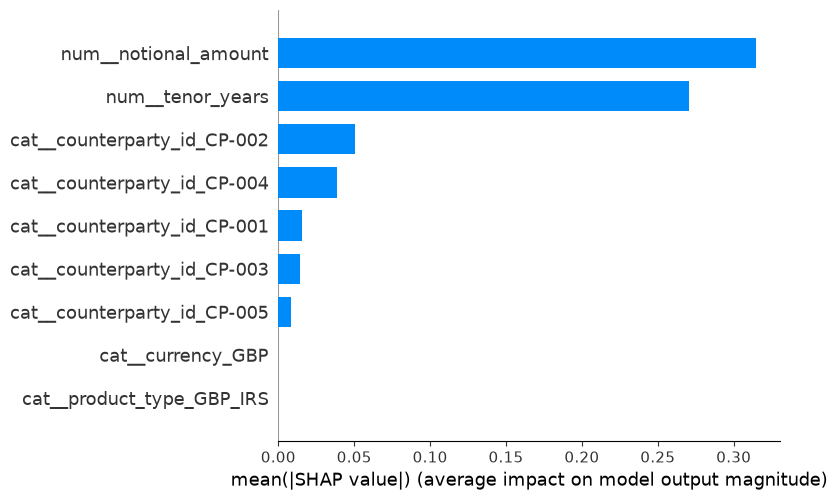

In [47]:
shap.summary_plot(
    shap_values.values,
    X_val_transformed,
    feature_names=feature_names,
    plot_type="bar",
    show=True
)

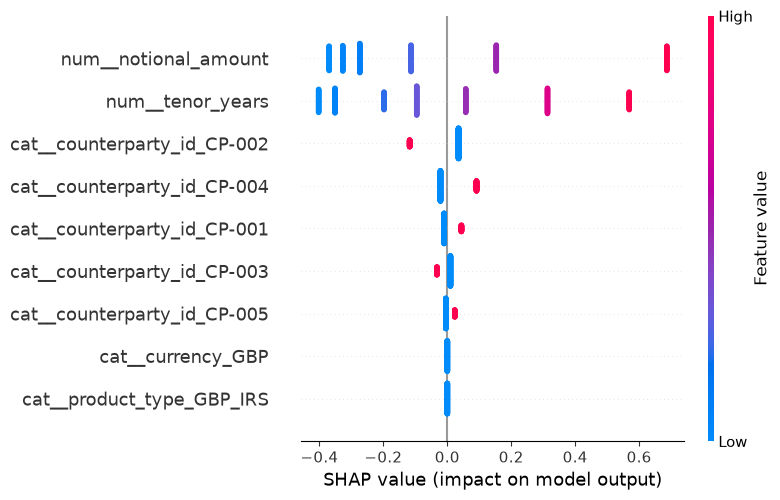

In [48]:
## Complete SHAP explanation
shap.summary_plot(
    shap_values.values,
    X_val_transformed,
    feature_names=feature_names,
    show=True
)

Trade ID: H-01401
Actual Outcome: 0
Predicted Rejection Probability: 0.1447


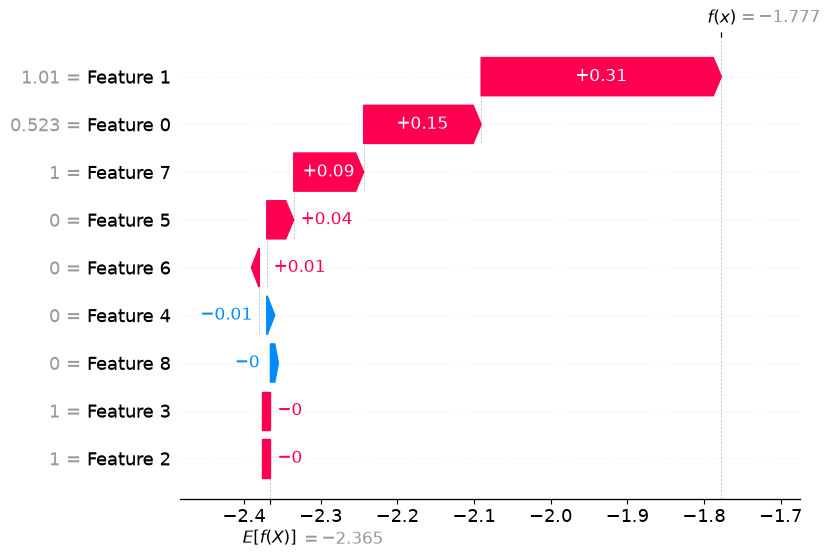

In [49]:
# Select one validation trade
sample_idx = 0

print("Trade ID:", val_df.iloc[sample_idx]["trade_id"])
print("Actual Outcome:", y_val.iloc[sample_idx])

print(
    "Predicted Rejection Probability:",
    round(
        final_model.predict_proba(
            X_val.iloc[[sample_idx]]
        )[0, 1],
        4
    )
)

shap.plots.waterfall(
    shap_values[sample_idx],
    max_display=10
)

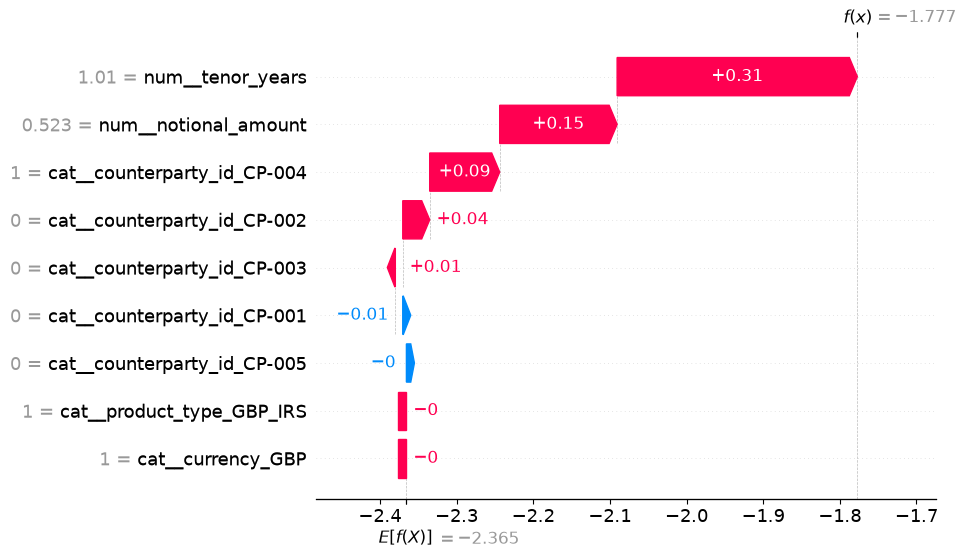

In [50]:
# Attach actual feature names to SHAP explanations
shap_values.feature_names = list(feature_names)

# Replot the individual explanation
shap.plots.waterfall(
    shap_values[sample_idx],
    max_display=10
)

In [52]:
## Save the model bundle

''' 
import joblib
import sklearn
import json
from pathlib import Path

# Create model directory
model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

# Final selected model
final_model = lr_model_org
final_threshold = 0.10

# Verify correct model
assert final_model.named_steps["classifier"].class_weight is None

# Save model and preprocessing together
joblib.dump(
    final_model,
    model_dir / "rejection_risk_pipeline.joblib"
)

# Save model metadata
metadata = {
    "model_name": "Logistic Regression",
    "model_version": "1.0.0",
    "threshold": final_threshold,
    "features": FEATURES,
    "target": TARGET,
    "random_seed": 42,
    "sklearn_version": sklearn.__version__,
    "test_pr_auc": 0.1376,
    "test_precision": 0.1616,
    "test_recall": 0.5517,
    "test_f1": 0.25,
    "data_type": "Synthetic OTC Trades"
}

with open(model_dir / "model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("Model and metadata saved successfully.")

'''

Model and metadata saved successfully.
